# Ejercicio 1 · Cómo se construye, entrena y ejecuta el agente

Este notebook desarrolla un circuito completo de **Double DQN para ejecutar una orden de compra**.
Una orden madre o CARE indica cuántos títulos comprar y dentro de qué plazo. El agente decide en cada
paso si espera o compra una orden hija de un título.

El objetivo del ejercicio 1 (3,5 puntos) es que funcionen el entorno, la interacción, la memoria,
el aprendizaje y la ejecución final, con decisiones documentadas. **Repartir las compras como un
TWAP es el objetivo del ejercicio 2.** El enunciado no exige motivar en detalle cada hiperparámetro
en este primer ejercicio; aquí explicamos su función sin presentar sus valores como óptimos.

**Cómo leerlo.** Los 15 apartados siguen las decisiones de diseño. Cada uno explica qué se hace,
por qué y qué función lo implementa. Las celdas `mostrar_codigo(...)` imprimen el código real
importado de `common/`; lo muestran para estudiarlo, sin redefinirlo ni ejecutarlo de nuevo.
Las celdas que sí realizan el experimento aparecen junto a su explicación. El entrenamiento completo
se lanza en el apartado 13 y el guardado final queda en el 15.

**El ciclo en una frase:** el entorno prepara una orden y entrega una observación; el agente elige
una acción; el entorno la ejecuta y devuelve recompensa y nueva observación; se guarda la experiencia
y, cada 64 interacciones, se ajusta la red con un lote de experiencias. Al terminar una orden comienza
otro episodio, conservando los pesos y la memoria.

```text
Histórico → entorno → observación [T, V] → agente → esperar/comprar
               ↑                                      │
               └──────── ejecutar la acción ──────────┘
                             │
                  recompensa + estado siguiente
                             ↓
                    memoria de experiencias
                             ↓ cada 64 pasos
                       actualizar la red
```

Un **paso** es una interacción con una fila del histórico. Un **episodio** es una orden, hasta
completarla o agotar su plazo. Una **actualización** es un ajuste de los pesos: no hay que esperar
al final del episodio para realizarla. Antes del entrenamiento se recogen 25 episodios sin aprender.

El retorno de RL es una suma de recompensas descontadas, no la rentabilidad de comprar y vender
una inversión. En este simulador no hay una venta posterior.

**Cambios respecto al LAB de partida** (`execution_lab.ipynb` del taller):

| Bloque original | Implementación utilizada | Motivo |
|---|---|---|
| Entorno, celda 7 | 13 funciones completadas en `common/env.py` | Separar simulación y experimento. |
| Agente, celda 3 | Double DQN en PyTorch, `common/agents.py` | Usar el entorno Python del proyecto; el enunciado permite PyTorch. |
| TWAP, celda 9 | `TWAPAgent` | Disponer de una referencia determinista. |
| Parámetros, celda 12 | Configuración explícita en este notebook | Identificar el experimento ejecutado. |
| Buffer, celda 16 | Llenado parcial con 25 episodios | Preparar experiencias sin llenar toda la memoria con la política inicial. |
| Bucle, celda 18 | `protocol.train` | Respetar el orden de Double DQN y reutilizarlo. |
| Evaluación, celda 20 | Rejillas fijas de train y test | Comparar sobre órdenes concretas y conservar las figuras. |

Referencias locales: [enunciado](../docs/raw/MIAX14/ejercicios_taller_rl.docx),
[registro de decisiones](../docs/DECISIONES.md) y [entorno del taller](../docs/teoria/08_entorno_best_execution.md).

## 1. Separar entorno, agente y entrenamiento

**Decisión.** El notebook coordina el experimento y `common/` contiene la implementación.
El entorno mantiene la orden y simula las ejecuciones; el agente elige acciones y aprende;
la recompensa define qué se premia; el protocolo organiza el ciclo y la evaluación.

**Justificación.** Esta separación permite cambiar la recompensa o la exploración sin duplicar
todo el entorno. También permite leer la explicación y consultar la función concreta que la respalda.
Se conserva el algoritmo Double DQN del LAB y se implementa su red en PyTorch (D-0.1 y D-0.3).
No necesitamos una tecnología determinada para que el orden del algoritmo sea correcto.

In [1]:
import os, sys, inspect, textwrap, hashlib
from pathlib import Path
from types import SimpleNamespace
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / "notebooks" / "common").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "notebooks"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from common import data as dt, rewards as rw, exploration as ex, protocol as pr, plots as pl
from common.env import BestExecutionEnv
from common.agents import DDQNAgent, TWAPAgent, QNetwork

torch.set_num_threads(1)
pd.set_option("display.precision", 3)
%matplotlib inline

def mostrar_codigo(*objetos, desde=None, hasta=None):
    """Muestra fuente real; desde/hasta delimitan opcionalmente un fragmento."""
    for objeto in objetos:
        fuente = textwrap.dedent(inspect.getsource(objeto))
        if desde is not None:
            fuente = fuente[fuente.index(desde):]
        if hasta is not None:
            fuente = fuente[:fuente.index(hasta)]
        archivo = Path(inspect.getfile(objeto)).relative_to(ROOT).as_posix()
        display(Markdown(f"**`{objeto.__qualname__}` · `{archivo}`**\n\n```python\n{fuente.rstrip()}\n```"))

## 2. Elegir los datos y separar su uso de lo que observa la red

**Decisión.** Trabajamos con Repsol (`REP`), uno de los activos permitidos. `dt.load` carga los
splits suministrados; el aprendizaje utiliza únicamente `DATA["train"]`. Test se reserva para
una evaluación descriptiva después de fijar la configuración (D-0.2).

**Qué utiliza el entorno del histórico:**

| Información | Uso técnico | ¿Entra en la red? |
|---|---|---|
| `ask1`, mejor vendedor | Precio de cada compra; también interviene en el mid. | No. |
| `bid1`, mejor comprador | Mid = (`ask1` + `bid1`) / 2. | No. |
| `cumvol`, volumen negociado acumulado | Diferencias de volumen entre observaciones; ponderación del VWAP. | No. |
| Día, índice temporal y orden de las filas | Elegir un tramo y avanzar una fila por paso. | Solo se entrega la fracción de tiempo restante, no la fecha. |
| Contadores de la orden simulada | Calcular tiempo restante y títulos por comprar. | Sí, como `[T, V]`. |

Los ficheros contienen además otras columnas, como `last`, `vask1` y `vbid1`, que este circuito
no usa para elegir acciones ni para su recompensa por defecto. El volumen del mercado y el volumen
de nuestra orden son cosas distintas: el primero pondera el VWAP y el segundo mide cuánto falta por comprar.

La siguiente celda enseña observaciones reales y el código que transforma precios y volumen.
En `_compute_episode_market_feat`, `diff()[t+1]` representa el volumen del intervalo siguiente a la
instantánea `t`: por eso se empareja `mid[:-1]` con las diferencias `[1:]`. Se trata de una
aproximación del VWAP con snapshots, no de reconstruir cada operación real del mercado.

In [2]:
ASSET = "REP"
DATA = dt.load(ASSET)
train = DATA["train"]
display(pd.DataFrame(dt.summary(DATA)).T)
primer_dia = next(iter(train))
display(train[primer_dia][["ask1", "bid1", "cumvol"]].head(3))
mostrar_codigo(dt.load, BestExecutionEnv._compute_episode_market_feat)

,dias,filas_por_dia
train,60,"[3177, 3178, 3179]"
val,30,"[3179, 3180, 3181]"
test,30,"[3179, 3180, 3181]"


,ask1,bid1,cumvol
time,,,
2018-01-02 13:00:00,15.00,14.995,1.429e+06
2018-01-02 13:00:05,15.01,15.005,1.431e+06
2018-01-02 13:00:10,15.01,15.000,1.432e+06


**`load` · `notebooks/common/data.py`**

```python
def load(asset: str = "REP") -> dict:
    """Devuelve {"train": {día: DataFrame}, "val": {...}, "test": {...}}."""
    with open(DATA_DIR / ASSETS[asset], "rb") as f:
        return pickle.load(f)
```

**`BestExecutionEnv._compute_episode_market_feat` · `notebooks/common/env.py`**

```python
def _compute_episode_market_feat(self) -> Tuple[float, pd.Series]:
    """(4) VWAP y volumen de mercado del episodio. Sin ejecuciones de mercado, el precio
    de cada bin es el mid; el volumen negociado durante el bin t es el del bin t+1
    (diferencia de cumvol)."""
    mid = (self.episode["ask1"] + self.episode["bid1"]) / 2
    self.market_ep_vol = self.episode["cumvol"].diff()
    self.market_ep_vol.iloc[0] = 0
    cum_vol = self.market_ep_vol.sum()
    self.episode_vwap = float((mid.values[:-1] * self.market_ep_vol.values[1:]).sum() / cum_vol) \
        if cum_vol > 0 else float(mid.iloc[0])
    # [MOD] arrays precalculados para el bucle de pasos
    self._mid = mid.values.astype(float)
    self._ask = self.episode["ask1"].values.astype(float)
    self._bin_vol = np.append(self.market_ep_vol.values[1:], 0.0).astype(float)
    self._cum_pv = np.cumsum(self._mid * self._bin_vol)
    self._cum_v = np.cumsum(self._bin_vol)
    return self.episode_vwap, self.market_ep_vol
```

## 3. Convertir una orden en un episodio variable

**Decisión.** Cada `reset()` limpia los contadores, genera una nueva orden y devuelve la primera
observación. Se sortea duración entre 400 y 600 pasos, tamaño entre el 7,5 % y el 12,5 % del número
de pasos, día y posición de inicio válida. Una fila corresponde aproximadamente a 5 segundos.

**Justificación.** El agente debe interactuar con distintas órdenes, en lugar de repetir una única
duración y un único inicio. Una orden de 50 títulos en 500 pasos deja margen para esperar.
Ese 10 % es **50 títulos / 500 pasos**, no participación en el volumen histórico del mercado.

`look_back=60` conserva 60 filas anteriores en `episode_full` para posibles variables adicionales.
Con `OBS_MODE="TV"` esas filas no se entregan a la red. `reset()` reinicia la orden, pero no borra
los pesos ni el buffer del agente. La rejilla de evaluación podrá forzar día, inicio, duración y tamaño.

In [3]:
mostrar_codigo(BestExecutionEnv._generate_episode_params,
               BestExecutionEnv._generate_episode, BestExecutionEnv.reset)

**`BestExecutionEnv._generate_episode_params` · `notebooks/common/env.py`**

```python
def _generate_episode_params(self, n_bins: Optional[int] = None, vol_care: Optional[int] = None):
    """(1) Duración uniforme en [400, 600] bins y orden CARE = U[0,075; 0,125] · bins."""
    lo, hi = self.bins_range
    self.episode_bins = int(n_bins) if n_bins is not None else int(self.rng.integers(lo, hi + 1))
    if vol_care is None:
        pct_bins = self.rng.uniform(*self.pct_range)
        vol_care = int(pct_bins * self.episode_bins)
    self.vol_care = int(vol_care)
    self.episode_full_len = self.episode_bins + self.look_back

    assert lo <= self.episode_bins <= hi
    assert int(self.episode_bins * self.pct_range[0]) <= self.vol_care <= int(self.episode_bins * self.pct_range[1])
    assert isinstance(self.vol_care, int)
```

**`BestExecutionEnv._generate_episode` · `notebooks/common/env.py`**

```python
def _generate_episode(self, day=None, start_pos: Optional[int] = None,
                      n_bins: Optional[int] = None, vol_care: Optional[int] = None):
    """(2) Día y hora de inicio. El original sortea una hora y repite si no cabe el
    episodio; aquí se sortea directamente una posición válida (mismo resultado, sin
    bucle). [MOD] día y posición forzables."""
    self._generate_episode_params(n_bins, vol_care)
    selected_day = day if day is not None else self.days[self.rng.integers(len(self.days))]
    data_day = self.data[selected_day]
    first, last = self.look_back, len(data_day) - self.episode_bins
    if last < first:
        raise ValueError(f"El día {selected_day} es demasiado corto para {self.episode_bins} bins")
    hour_pos = int(start_pos) if start_pos is not None else int(self.rng.integers(first, last + 1))
    assert first <= hour_pos <= last, "posición de inicio fuera de rango"
    initial_position = hour_pos - self.look_back
    final_position = hour_pos + self.episode_bins
    self.selected_day = selected_day
    self.hour_pos = hour_pos
    self.episode_full = data_day.iloc[initial_position:final_position]
    self.episode = data_day.iloc[hour_pos:final_position]
    assert len(self.episode_full) == self.episode_full_len
```

**`BestExecutionEnv.reset` · `notebooks/common/env.py`**

```python
def reset(self, day=None, start_pos: Optional[int] = None, n_bins: Optional[int] = None,
          vol_care: Optional[int] = None) -> np.ndarray:
    """Nuevo episodio; devuelve la primera observación."""
    self._reset_env_episode_params()
    self._generate_episode(day, start_pos, n_bins, vol_care)
    self._compute_episode_market_feat()
    return self.observation_builder()
```

## 4. Construir un estado pequeño y normalizado

**Decisión.** La entrada es `s = [T, V]`, con `T` = tiempo restante / plazo inicial y
`V` = títulos pendientes / tamaño inicial. Por ejemplo, `[0.60, 0.80]` significa que queda
el 60 % del tiempo y el 80 % de la orden por comprar.

**Justificación.** Normalizar permite compartir la red entre duraciones y tamaños distintos.
Para seguir un plan uniforme, comparar ambas fracciones informa de si se va adelantado o retrasado.
No obstante, un título cambia `V` en `1/n`, así que normalizar no elimina todas las diferencias entre órdenes.

**Límite de información.** La red no observa el precio actual, el spread, la tendencia ni el VWAP
final. Dos mercados con precios distintos pueden producir el mismo `[T, V]` y, por tanto, la misma
decisión de la red. Este estado es coherente para estudiar seguimiento TWAP; resulta limitado para
buscar compras baratas. El histórico puede ser conocido por el simulador sin ser observable por el agente.

In [4]:
mostrar_codigo(BestExecutionEnv.time_left, BestExecutionEnv.vol_left,
               BestExecutionEnv.observation_builder)

**`BestExecutionEnv.time_left` · `notebooks/common/env.py`**

```python
def time_left(self) -> float:
    return (self.episode_bins - self.state_pos) / self.episode_bins
```

**`BestExecutionEnv.vol_left` · `notebooks/common/env.py`**

```python
def vol_left(self) -> float:
    return (self.vol_care - self.exec_vol) / self.vol_care
```

**`BestExecutionEnv.observation_builder` · `notebooks/common/env.py`**

```python
def observation_builder(self) -> np.ndarray:
    """(3) Tiempo restante y volumen restante en tanto por uno ([MOD] opcional d = V - T)."""
    time_left, vol_left = self.time_left(), self.vol_left()
    if self.obs_mode == "TVd":
        return np.array([time_left, vol_left, vol_left - time_left])
    return np.array([time_left, vol_left])
```

## 5. Elegir entre esperar y comprar un título

**Decisión.** Hay dos acciones: `0` espera y `1` compra un título al `ask1` de la fila actual.
El agente decide el momento, mientras que el histórico determina el precio de la ejecución.

**Justificación.** Fijar el tamaño de las órdenes hijas concentra el problema en cuándo ejecutar.
Se asume ejecución inmediata al mejor vendedor, sin impacto de mercado, comisiones, colas ni
ejecuciones parciales. Nuestra compra no altera las filas históricas posteriores.

`_record` registra precio y cantidad, incrementa `exec_vol`, recalcula el precio medio de nuestras
compras y obtiene la recompensa. Esperar registra cantidad cero: no representa una compra a precio cero.

In [5]:
mostrar_codigo(BestExecutionEnv._agg_action, BestExecutionEnv._do_nothing,
               BestExecutionEnv._record, BestExecutionEnv._compute_algo_vwap)

**`BestExecutionEnv._agg_action` · `notebooks/common/env.py`**

```python
def _agg_action(self) -> float:
    """(7) Compra agresiva de 1 título al ask1 del step."""
    return self._record(float(self._ask[self.state_pos]), 1)
```

**`BestExecutionEnv._do_nothing` · `notebooks/common/env.py`**

```python
def _do_nothing(self) -> float:
    """(9) No hacer nada: precio y volumen 0."""
    return self._record(0.0, 0)
```

**`BestExecutionEnv._record` · `notebooks/common/env.py`**

```python
def _record(self, price: float, vol: int) -> float:
    self.price_hist.append(price)
    self.vol_hist.append(vol)
    self.exec_vol += vol
    self.algo_vwap = self._compute_algo_vwap()
    self.algo_vwap_hist.append(self.algo_vwap)
    return self._compute_reward(price, vol)
```

**`BestExecutionEnv._compute_algo_vwap` · `notebooks/common/env.py`**

```python
def _compute_algo_vwap(self) -> float:
    """(8) VWAP del algoritmo hasta el step actual (nan si aún no ha comprado)."""
    v_arr = np.asarray(self.vol_hist, dtype=float)
    if v_arr.sum() == 0:
        return np.nan
    p_arr = np.asarray(self.price_hist, dtype=float)
    return float((p_arr * v_arr).sum() / v_arr.sum())
```

## 6. Mantener la recompensa del LAB y explicar su alcance

**Decisión.** Si espera, la recompensa es cero; si compra, es
`(VWAP del episodio − precio de compra) / VWAP del episodio`. `Default` hereda `done() = 0`,
por lo que no hay penalización terminal por títulos pendientes en este ejercicio.

**Justificación.** Conservamos el objetivo original para comprobar el circuito antes de cambiarlo
en el ejercicio 2. Con VWAP 100, comprar a 99 da `+0.01` y comprar a 101 da `−0.01`.
La recompensa por compra no se multiplica por el volumen, pues cada compra es de un título.

**Retorno en RL.** La red intenta aproximar `r_t + gamma*r_(t+1) + ...`, no una rentabilidad
de compra y venta. `gamma` descuenta recompensas lejanas; la recompensa de un solo paso y el retorno
acumulado son conceptos diferentes.

**Límite que condiciona la interpretación.** El VWAP final se calcula con todo el episodio y sirve
como referencia retrospectiva. No se introduce en `[T, V]`. La red no puede distinguir dos situaciones
con el mismo estado y precios distintos: como mucho aprende regularidades medias asociadas al tiempo,
volumen pendiente y consecuencias de terminar. El precio no tiene por qué ser aleatorio; sencillamente
no se observa. Este diseño no demuestra capacidad de anticipar oportunidades de precio y tampoco
incentiva explícitamente repartir las compras de forma uniforme ni completar toda la orden.

In [6]:
mostrar_codigo(rw.Default.step, rw.Reward.done)
example = SimpleNamespace(episode_vwap=100.0, vol_care=50, exec_vol=25)
reward = rw.Default()
display(pd.DataFrame({
    "decisión": ["esperar", "comprar a 99", "comprar a 101", "terminar con 25 pendientes"],
    "recompensa": [reward.step(example, 99.0, 0), reward.step(example, 99.0, 1),
                   reward.step(example, 101.0, 1), reward.done(example)]
}))
assert reward.step(example, price=99.0, vol=0) == 0.0
assert np.isclose(reward.step(example, price=99.0, vol=1), 0.01)
assert reward.done(example) == 0.0

**`Default.step` · `notebooks/common/rewards.py`**

```python
def step(self, env, price, vol):
    if vol == 0:
        return 0.0
    return (env.episode_vwap - price) / env.episode_vwap
```

**`Reward.done` · `notebooks/common/rewards.py`**

```python
def done(self, env) -> float:
    return 0.0
```

,decisión,recompensa
0,esperar,0.00
1,comprar a 99,0.01
2,comprar a 101,-0.01
3,terminar con 25 pendientes,0.00


## 7. Terminar al completar la orden o agotar el tiempo

**Decisión.** `done` se activa cuando `exec_vol >= vol_care` o `state_pos >= episode_bins`.
El entorno devuelve entonces `siguiente_estado=None`; el agente guarda esa transición como terminal.

**Justificación.** Una orden deja de generar decisiones al completarse o vencer. Terminar el episodio
no significa necesariamente completar la compra: si vence el plazo pueden quedar títulos pendientes.
Al aprender de una transición terminal, el objetivo será solo la recompensa recibida, sin valor futuro.

`step()` ejecuta primero la acción y calcula su recompensa, avanza el contador temporal y comprueba
la parada. Si termina, añade una única recompensa terminal (aquí cero). Así, la observación devuelta
refleja el tiempo y volumen después de la acción.

In [7]:
mostrar_codigo(BestExecutionEnv._compute_stop_conditions, BestExecutionEnv._compute_done,
               BestExecutionEnv.step)

**`BestExecutionEnv._compute_stop_conditions` · `notebooks/common/env.py`**

```python
def _compute_stop_conditions(self) -> Tuple[bool, bool]:
    """(10) Tiempo agotado, orden completada."""
    is_bins_complete = self.state_pos >= self.episode_bins
    is_ord_complete = self.exec_vol >= self.vol_care
    return is_bins_complete, is_ord_complete
```

**`BestExecutionEnv._compute_done` · `notebooks/common/env.py`**

```python
def _compute_done(self) -> bool:
    """(11) Termina si se cumple cualquiera de las condiciones de parada."""
    is_bins_complete, is_ord_complete = self._compute_stop_conditions()
    return is_bins_complete or is_ord_complete
```

**`BestExecutionEnv.step` · `notebooks/common/env.py`**

```python
def step(self, action: int):
    """Evalúa la acción, calcula la recompensa y devuelve (obs, r, done, info)."""
    market_vwap = self._compute_market_vwap()
    act_fn = self.actions_fn.get(int(action))
    if act_fn is None:
        raise ValueError(f"Invalid action {action}. Valid actions {list(self.actions_fn)}")
    self.reward.before_step(self, int(action))
    reward = act_fn()
    self.actions_hist.append(int(action))
    self.market_vwap_hist.append(market_vwap)
    self.reward_hist.append(reward)
    self.state_pos += 1
    done = self._compute_done()
    if done:
        reward += self._compute_done_reward()
        return None, reward, done, {}
    return self.observation_builder(), reward, done, {}
```

**Ejemplo completo de intercambio de información con datos reales.** Esta demostración utiliza un
entorno independiente y seis acciones elegidas a mano. No entrena una red ni consume el generador
del entorno de entrenamiento. La tabla separa lo que ve el agente (`T`, `V`) de lo que solo utiliza
el simulador (`ask1` y VWAP). Se fuerza una orden de 50 títulos en 500 pasos.

In [8]:
demo_env = BestExecutionEnv(train, reward=rw.Default(), seed=123, obs_mode="TV")
demo_s = demo_env.reset(day=primer_dia, start_pos=60, n_bins=500, vol_care=50)
demo_filas = []
for demo_a in [1, 0, 0, 1, 0, 1]:
    demo_t = demo_env.state_pos
    demo_ask = float(demo_env._ask[demo_t])
    demo_s1, demo_r, demo_done, _ = demo_env.step(demo_a)
    demo_filas.append({
        "paso": demo_t, "T antes (visible)": demo_s[0], "V antes (visible)": demo_s[1],
        "acción manual": "comprar" if demo_a else "esperar",
        "ask (solo entorno)": demo_ask, "VWAP final (solo entorno)": demo_env.episode_vwap,
        "precio ejecutado": demo_ask if demo_a else np.nan, "recompensa": demo_r,
        "T después": demo_s1[0], "V después": demo_s1[1], "terminado": demo_done
    })
    demo_s = demo_s1
display(pd.DataFrame(demo_filas))

,paso,T antes (visible),V antes (visible),acción manual,ask (solo entorno),VWAP final (solo entorno),precio ejecutado,recompensa,T después,V después,terminado
0,0,1.000,1.00,comprar,15.025,15.002,15.025,-0.002,0.998,0.98,False
1,1,0.998,0.98,esperar,15.025,15.002,NaN,0.000,0.996,0.98,False
2,2,0.996,0.98,esperar,15.025,15.002,NaN,0.000,0.994,0.98,False
3,3,0.994,0.98,comprar,15.025,15.002,15.025,-0.002,0.992,0.96,False
4,4,0.992,0.96,esperar,15.025,15.002,NaN,0.000,0.990,0.96,False
5,5,0.990,0.96,comprar,15.025,15.002,15.025,-0.002,0.988,0.94,False


## 8. Aproximar los valores de las acciones con una red

**Decisión.** La arquitectura elegida es `2 → 64 → 64 → 2`: dos entradas, dos capas ocultas
ReLU y dos salidas lineales, una para `Q(s, esperar)` y otra para `Q(s, comprar)`.

**Justificación.** Los estados son continuos y una red permite compartir lo aprendido entre
observaciones próximas. ReLU permite relaciones no lineales; la salida lineal admite valores Q
positivos o negativos. No se aplica softmax: los valores Q no son probabilidades y no tienen que sumar uno.

El agente compara ambas salidas mediante `argmax`. Es una estimación de retorno condicionado a su
información disponible, no una previsión del próximo precio. Usar una red permite practicar Deep RL,
pero no prueba que sea necesaria ni superior a una regla sencilla para este estado.

In [9]:
mostrar_codigo(QNetwork, DDQNAgent._act_no_explore)

**`QNetwork` · `notebooks/common/agents.py`**

```python
class QNetwork(nn.Module):
    """Igual que DDQNAgent.network del original: 2 capas ocultas ReLU y salida lineal."""

    def __init__(self, n_features: int, n_actions: int, hidden: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )

    def forward(self, x):
        return self.net(x)
```

**`DDQNAgent._act_no_explore` · `notebooks/common/agents.py`**

```python
def _act_no_explore(self, s) -> int:
    return int(np.argmax(self.getQs(np.asarray(s).reshape(1, -1), self.primary_model)))
```

## 9. Explorar al principio y reducir epsilon

**Decisión.** Durante el entrenamiento, con probabilidad `epsilon` se explora; en los demás casos
se elige la acción con mayor Q. Se parte de `epsilon=1.0`, se reduce linealmente y se mantiene un
mínimo de `0.02`. La excepción es la compra inicial impuesta, explicada en el apartado 10.

**Justificación.** Al principio los pesos se inicializan aleatoriamente y las estimaciones no son
fiables. Explorar recoge experiencias; reducir epsilon permite usar progresivamente lo aprendido.
Con 4.000 episodios y esta fórmula se alcanza el mínimo aproximadamente tras los primeros 2.000:

```python
epsilon_decay = (1.0 - 0.02) / (0.5 * 4000)  # 0.00049 por episodio
```

Epsilon cambia al terminar cada episodio, mientras que los pesos pueden cambiar dentro del episodio.
Este calendario depende del número de episodios, no de que el agente mejore; el ejercicio 3 estudia
precisamente esa alternativa. Con epsilon 1 no se compra siempre: se llama al muestreador del entorno.

In [10]:
mostrar_codigo(DDQNAgent.act, ex.LinearDecay)

**`DDQNAgent.act` · `notebooks/common/agents.py`**

```python
def act(self, s) -> int:
    if self.force_first_buy and self.env.state_pos == 0:
        return 1
    if self._trainable and self.rng.random() < self.epsilon:
        return self.env.action_sample(rng=self.rng)
    return self._act_no_explore(s)
```

**`LinearDecay` · `notebooks/common/exploration.py`**

```python
class LinearDecay:
    def __init__(self, epsilon=1.0, min_epsilon=0.05, epsilon_decay=None, nepisodes=None, frac=0.5):
        """Si no se da ``epsilon_decay``, se calcula para llegar a ``min_epsilon`` en
        ``frac · nepisodes`` episodios (como en los notebooks de rl-material)."""
        self.start = epsilon
        self.min_epsilon = min_epsilon
        if epsilon_decay is None:
            epsilon_decay = (epsilon - min_epsilon) / max(1, frac * nepisodes)
        self.epsilon_decay = epsilon_decay

    def init(self, agent):
        agent.epsilon = self.start

    def on_episode_end(self, agent, episode):
        agent.epsilon = max(agent.epsilon - self.epsilon_decay, self.min_epsilon)

    def on_eval(self, agent, metric):
        pass
```

## 10. Ajustar la exploración al tamaño de la orden y conservar la compra inicial

**Decisión.** Al explorar se compra con `p = n/N`, donde `n` son títulos iniciales y `N` pasos
disponibles. Para 50 títulos en 500 pasos, `p=0.10` (D-1.2).

**Justificación.** Con `p=0.5` se completarían 50 compras en unos 100 pasos de media: el agente
recogería pocas experiencias cerca del vencimiento. Con `p=n/N` el ritmo medio se aproxima al plan,
aunque cada trayectoria puede agrupar compras o dejar pendientes. No es una garantía de completitud
ni una política TWAP determinista.

Se mantiene además `force_first_buy=True`: si `state_pos == 0`, `act()` devuelve comprar antes de
considerar epsilon o la red. **La primera compra es una regla impuesta, también en evaluación**.
Se conserva por continuidad con el LAB, no porque la red la haya aprendido ni porque garantice acabar.

In [11]:
mostrar_codigo(BestExecutionEnv.action_sample)
# Fragmento exacto de act(): esta condición tiene prioridad sobre explorar o usar la red.
mostrar_codigo(DDQNAgent.act, desde="if self.force_first_buy", hasta="if self._trainable")

**`BestExecutionEnv.action_sample` · `notebooks/common/env.py`**

```python
def action_sample(self, rng=None, p: Optional[float] = None) -> int:
    """(13) Acción aleatoria. Por defecto compra con probabilidad ρ = vol_care / bins,
    el ritmo de un TWAP: con p = 0,5 el agente acabaría la orden en ~2n pasos y casi
    nunca vería la parte final del episodio. ``rng`` permite usar el generador del
    agente para no consumir el del entorno ([MOD])."""
    rng = rng if rng is not None else self.rng
    p = self.vol_care / self.episode_bins if p is None else p
    return int(rng.random() < p)
```

**`DDQNAgent.act` · `notebooks/common/agents.py`**

```python
if self.force_first_buy and self.env.state_pos == 0:
        return 1
```

## 11. Guardar experiencias y llenar parcialmente el buffer

**Decisión.** Se almacenan transiciones `(s, a, r, s1)` en una cola de hasta 50.000 elementos;
al llenarse, se descartan los más antiguos. Si la transición es terminal se guarda `s1=None`.

Antes de aprender, `fill_buffer` recoge 25 episodios con epsilon 1, manteniendo la compra inicial
impuesta. Se ejecutan y guardan acciones, pero no se llama a `learn()`. Al acabar restaura epsilon
y el modo previo del agente. El número de experiencias depende de la duración real de esos episodios.

**Justificación.** El llenado parcial, recomendado en clase y registrado como D-1.1, prepara ejemplos
variados sin ocupar toda la memoria con la política inicial. El replay mezcla distintos momentos
y episodios, reduciendo la dependencia entre observaciones consecutivas.

Cada lote contiene 63 experiencias aleatorias sin reemplazo entre las anteriores y la última
experiencia añadida: **Combined Experience Replay**. Así se combina variedad con uso inmediato de
la transición reciente. Una experiencia puede reutilizarse en actualizaciones posteriores.

La creación del agente y el llenado se ejecutan juntos al inicio del apartado 13, una vez fijados
todos los parámetros. Mostrar las funciones aquí no adelanta ese entrenamiento.

In [12]:
mostrar_codigo(DDQNAgent.__init__, desde="self.buffer =", hasta="self.hidden_neurons")
mostrar_codigo(DDQNAgent.experience, DDQNAgent.sample, pr.fill_buffer)

**`DDQNAgent.__init__` · `notebooks/common/agents.py`**

```python
self.buffer = deque(maxlen=buffer_size)
```

**`DDQNAgent.experience` · `notebooks/common/agents.py`**

```python
def experience(self, s, a, r, s1, done=False):
    if done:
        s1 = None
    self.buffer.append((s, a, r, s1))
```

**`DDQNAgent.sample` · `notebooks/common/agents.py`**

```python
def sample(self):
    """Combined Experience Replay: batch_size - 1 experiencias al azar más la última."""
    idx = self.rng.choice(len(self.buffer) - 1, size=self.batch_size - 1, replace=False)
    idx = np.append(idx, len(self.buffer) - 1)
    return [self.buffer[i] for i in idx]
```

**`fill_buffer` · `notebooks/common/protocol.py`**

```python
def fill_buffer(agent, env, n_episodes=25):
    """Llena parcialmente el buffer con episodios aleatorios (p = ρ) antes de aprender.
    El original llena ``buffer_size`` pasos enteros; en clase se recomendó 20-30 episodios."""
    old_eps, old_train = agent.epsilon, agent._trainable
    agent.epsilon, agent._trainable = 1.0, True
    steps = 0
    for _ in range(n_episodes):
        s = env.reset()
        while True:
            a = agent.act(s)
            s1, r, done, _ = env.step(a)
            agent.experience(s, a, r, s1, done)
            s, steps = s1, steps + 1
            if done:
                break
    agent.epsilon, agent._trainable = old_eps, old_train
    return steps
```

## 12. Aprender con Double DQN y una red objetivo

**Decisión.** La red principal aprende mediante Adam y error cuadrático medio. Una segunda red,
la red objetivo, proporciona la evaluación del siguiente estado. Sus pesos se copian periódicamente
desde la principal; no recibe las actualizaciones del optimizador.

Para cada experiencia del lote:

1. La red principal estima `Q(s,a)` para la acción que se ejecutó.
2. En `s1`, la principal elige la acción de mayor Q.
3. La red objetivo valora esa acción y se construye el objetivo de aprendizaje.
4. Se calcula la diferencia, se propaga el gradiente y se actualiza la principal.

$$
y = r + \gamma(1-\mathrm{terminal})\,
Q_{\mathrm{objetivo}}\left(s',\arg\max_{a'} Q_{\mathrm{principal}}(s',a')\right)
$$

**Justificación.** Separar selección y evaluación busca reducir la sobreestimación de Q.
Mantener la red objetivo fija durante varias actualizaciones reduce el movimiento de la referencia
con la que aprende la principal. `torch.no_grad()` evita propagar gradientes por ese objetivo.
El objetivo contiene una estimación, no es el retorno futuro verdadero conocido de antemano.

**Ejemplo numérico ilustrativo:** si la recompensa es `0.01`, la estimación del futuro es `0.02`
y gamma es `0.99`, el objetivo es `0.0298`. Si la transición es terminal, el objetivo es solo `0.01`.
Si la red había estimado `0.005`, el error orienta el ajuste de los pesos; un paso de Adam no obliga
a que la nueva salida coincida exactamente con el objetivo.

`zero_grad()` limpia gradientes anteriores, `backward()` calcula los nuevos y `step()` modifica
los pesos. El MSE se calcula sobre las 64 experiencias del lote, no sobre un episodio completo.

In [13]:
mostrar_codigo(DDQNAgent.__init__, desde="self.primary_model =", hasta="self._trainable")
mostrar_codigo(DDQNAgent.learn, DDQNAgent.update_target)

**`DDQNAgent.__init__` · `notebooks/common/agents.py`**

```python
self.primary_model = QNetwork(self.n_features, self.na, hidden_neurons)
    self.optimizer = torch.optim.Adam(self.primary_model.parameters(), lr=alpha)
    self.loss_fn = nn.MSELoss()
    # Double Deep Q-Learning: copia congelada que evalúa la acción elegida por la primaria
    self.target_model = QNetwork(self.n_features, self.na, hidden_neurons)
    self.update_target()
```

**`DDQNAgent.learn` · `notebooks/common/agents.py`**

```python
def learn(self) -> float:
    """Un paso de descenso por gradiente sobre un batch; devuelve el MSE."""
    if len(self.buffer) < self.batch_size:
        return float("nan")
    batch = self.sample()
    s = torch.as_tensor(np.array([b[0] for b in batch]), dtype=torch.float32)
    a = torch.as_tensor([b[1] for b in batch], dtype=torch.int64)
    r = torch.as_tensor([b[2] for b in batch], dtype=torch.float32)
    not_done = torch.as_tensor([b[3] is not None for b in batch])
    s1 = torch.zeros_like(s)
    if not_done.any():
        s1[not_done] = torch.as_tensor(np.array([b[3] for b in batch if b[3] is not None]), dtype=torch.float32)

    with torch.no_grad():
        best_next = self.primary_model(s1).argmax(dim=1, keepdim=True)  # la primaria elige...
        q_next = self.target_model(s1).gather(1, best_next).squeeze(1)  # ...y la target evalúa
        target = r + self.gamma * q_next * not_done.float()

    q = self.primary_model(s).gather(1, a.unsqueeze(1)).squeeze(1)
    loss = self.loss_fn(q, target)
    self.optimizer.zero_grad()
    loss.backward()
    self.optimizer.step()
    return float(loss.item())
```

**`DDQNAgent.update_target` · `notebooks/common/agents.py`**

```python
def update_target(self):
    self.target_model.load_state_dict(self.primary_model.state_dict())
```

## 13. Ejecutar el ciclo en el orden correcto y entrenar dentro de cada episodio

**Decisión.** Se fijan los siguientes parámetros y se conservan la recompensa y el presupuesto
del experimento actual. Son una configuración de trabajo, no una demostración de optimalidad.

| Parámetro | Valor | Función y motivo |
|---|---|---|
| `gamma` | 0,99 | Da peso al futuro; no equivale a valorar igual todo el horizonte de 400–600 pasos. |
| `alpha` | 0,001 | Controla el tamaño de los ajustes de Adam. |
| Capas ocultas | 64 y 64 | Capacidad moderada para dos entradas y dos acciones. |
| `batch_size` | 64 | Experiencias utilizadas en cada actualización. |
| `buffer_size` | 50.000 | Permite reutilizar experiencias de muchos episodios; capacidad máxima. |
| `fill_episodes` | 25 | Recogida inicial sin aprendizaje. |
| `nepisodes` | 4.000 | Presupuesto fijo; no se aplica parada por mejora en este ejercicio. |
| `learn_after` | 64 | Una actualización de la principal cada 64 interacciones. |
| `update_target_after` | 640 | Copia de la principal a la objetivo cada 640 interacciones. |
| `eval_every` | 250 | Evaluación greedy en 27 órdenes fijas de validación. |
| `SEED` | 0 | Reproducción de esta ejecución; se explica junto al guardado en el apartado 15. |

`batch_size` y `learn_after` son conceptos diferentes aunque aquí coincidan: tamaño del lote frente
a frecuencia de actualización. El contador de interacciones continúa entre episodios dentro de
esta llamada a `train`, por lo que una actualización puede mezclar experiencias de distintas órdenes.

**Orden real:** `reset → act → step → experience → learn cuando corresponde → nueva decisión`.
Antes de crear las redes se fija la semilla; a continuación se llena el buffer y se lanza un único
entrenamiento de 4.000 episodios. La función que se muestra después contiene el bucle que realmente se usa.

In [14]:
# Parámetros del agente
epsilon, min_epsilon = 1.0, 0.02
gamma, alpha = 0.99, 1e-3
buffer_size, batch_size, hidden_neurons = 50_000, 64, 64
# Parámetros del entrenamiento
nepisodes = 4000
epsilon_decay = (epsilon - min_epsilon) / (0.5 * nepisodes)
learn_after = batch_size
update_target_after = 10 * learn_after
SEED, fill_episodes = 0, 25
force_first_buy = True
OBS_MODE = "TV"
eval_every = 250
CHECKPOINT = pr.MODELS / "ej1_ddqn"
GRID_VAL = pr.make_grid(DATA["val"], n_days=3, seed=0)

CONFIG = dict(asset=ASSET, reward="default", terminal_reward=0.0, obs_mode=OBS_MODE,
              look_back=60, bins_range=[400, 600], pct_range=[0.075, 0.125],
              gamma=gamma, alpha=alpha, epsilon=epsilon, min_epsilon=min_epsilon,
              epsilon_decay=epsilon_decay, buffer_size=buffer_size, batch_size=batch_size,
              hidden_neurons=hidden_neurons, nepisodes=nepisodes, learn_after=learn_after,
              update_target_after=update_target_after, fill_episodes=fill_episodes,
              force_first_buy=force_first_buy, seed=SEED, grid_seed=0, grid_days=3,
              torch_threads=torch.get_num_threads(), eval_every=eval_every,
              checkpoint_metric="execution", selection_split="val", validation_grid=GRID_VAL)
CONFIG["source_sha256"] = {
    name: hashlib.sha256((ROOT / "notebooks" / "common" / f"{name}.py").read_bytes()).hexdigest()
    for name in ("env", "rewards", "agents", "protocol", "exploration", "data", "plots")
}

# La semilla se fija ANTES de inicializar la red (véase el apartado 15).
pr.set_seeds(SEED)
env = BestExecutionEnv(train, look_back=60, reward=rw.Default(), seed=SEED, obs_mode=OBS_MODE)
agent = DDQNAgent(env, gamma=gamma, epsilon=epsilon, alpha=alpha, batch_size=batch_size,
                  buffer_size=buffer_size, hidden_neurons=hidden_neurons, seed=SEED,
                  force_first_buy=force_first_buy)
steps = pr.fill_buffer(agent, env, n_episodes=fill_episodes)
print(f"Llenado sin aprendizaje: {len(agent.buffer)} experiencias, {steps} interacciones")
print("Arquitectura que se va a entrenar:")
print(agent.primary_model)

Llenado sin aprendizaje: 12202 experiencias, 12202 interacciones
Arquitectura que se va a entrenar:
QNetwork(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [15]:
mostrar_codigo(pr.train)

**`train` · `notebooks/common/protocol.py`**

```python
def train(agent, env, nepisodes, exploration, learn_after=None, update_target_after=None,
          eval_data=None, eval_grid=None, eval_every=25, eval_reward=None,
          checkpoint=None, stop_patience=None, stop_min_delta=0.05, stop_target=None,
          start_episode=0, log_every=25, verbose=True,
          checkpoint_metric="max_err", checkpoint_config=None):
    """Bucle del notebook original (LAB celda 18) con ganchos para los ejercicios 3 y 4.

    - exploration: LinearDecay o ImprovementEpsilon (on_episode_end / on_eval).
    - eval_*: cada ``eval_every`` episodios, evaluación greedy en la rejilla fija; la
      métrica de mejora es el max_err medio.
    - checkpoint: ruta base; guarda el mejor modelo (``*_best.pt``) y el último (``*_last.pt``).
      También evalúa el episodio final si no coincide con eval_every.
      ``checkpoint_metric``: max_err (defecto) o execution (más órdenes completas,
      menos pendientes y mayor slippage, en ese orden). No cambia el reward.
      ``checkpoint_config`` añade la configuración a ambos archivos.
      Exploración adaptativa y parada siguen utilizando max_err.
    - stop_patience: parada si la métrica no mejora ``stop_min_delta`` en ese número de
      evaluaciones; stop_target: parada si la métrica baja de ese valor.
    Devuelve (DataFrame por episodio, DataFrame por evaluación).
    """
    learn_after = learn_after or agent.batch_size
    update_target_after = update_target_after or 10 * learn_after
    if checkpoint_metric not in ("max_err", "execution"):
        raise ValueError(f"Unknown checkpoint metric: {checkpoint_metric}")
    if eval_grid is not None and (not eval_grid or eval_data is None or eval_every <= 0):
        raise ValueError("Evaluation needs data, a nonempty grid and eval_every > 0")
    if checkpoint and eval_grid is None:
        raise ValueError("Checkpoint selection needs an evaluation grid")
    agent.set_trainable(True)
    learn_counter, mse = 0, np.nan
    ep_rows, ev_rows = [], []
    best, since_best = np.inf, 0
    best_score = None
    t0 = time.time()
    for episode in range(start_episode, start_episode + nepisodes):
        s = env.reset()
        step, cum_reward, dis_cum_reward = 0, 0.0, 0.0
        while True:
            a = agent.act(s)
            s1, r, done, _ = env.step(a)
            agent.experience(s, a, r, s1, done)
            learn_counter += 1
            cum_reward += r
            dis_cum_reward += agent.gamma ** step * r
            s = s1
            step += 1
            if not learn_counter % learn_after:
                mse = agent.learn()
            if not learn_counter % update_target_after:
                agent.update_target()
            if done:
                exploration.on_episode_end(agent, episode)
                ep_rows.append({"episode": episode, "steps": step, "reward": cum_reward,
                                "disc_reward": dis_cum_reward, "mse": mse, "epsilon": agent.epsilon,
                                "completed": env.exec_vol >= env.vol_care, "N": env.episode_bins, "n": env.vol_care})
                break
        if verbose and log_every and not (episode + 1) % log_every:
            last = pd.DataFrame(ep_rows[-log_every:])
            print(f"Episode {episode + 1}: steps {last.steps.mean():.0f}, rew {last.reward.mean():.3f}, "
                  f"mse {mse:.4f}, eps {agent.epsilon:.2f}, {time.time() - t0:.0f}s")
        if eval_grid is not None and (not (episode + 1) % eval_every or
                                      (checkpoint and episode + 1 == start_episode + nepisodes)):
            ev = evaluate(agent, eval_data, eval_grid, reward=eval_reward, obs_mode=env.obs_mode, with_twap=False)
            metric = float(ev.max_err.mean())
            score = _checkpoint_score(ev, checkpoint_metric)
            # El criterio por defecto conserva stop_min_delta para los ejercicios existentes.
            is_best = (metric < best - stop_min_delta if checkpoint_metric == "max_err"
                       else best_score is None or score > best_score)
            if is_best:
                best_score = score
            exploration.on_eval(agent, metric)
            agent.set_trainable(True)
            ev_rows.append({"episode": episode + 1, "max_err": metric, "mean_err": ev.mean_err.mean(),
                            "completed": ev.completed.mean(), "pending": ev.pending.mean(),
                            "slippage_bps": ev.slippage_bps.mean(), "return": ev["return"].mean(),
                            "epsilon": agent.epsilon, "is_best": is_best})
            if checkpoint:
                metadata = dict(episode=episode + 1, metric=metric, checkpoint_metric=checkpoint_metric,
                                selection_score=score, validation=ev_rows[-1].copy())
                if checkpoint_config is not None:
                    metadata["config"] = checkpoint_config
                agent.save(f"{checkpoint}_last.pt", **metadata)
                if is_best:
                    agent.save(f"{checkpoint}_best.pt", **metadata)
            if verbose:
                print(f"Eval {episode + 1}: completas {int(ev.completed.sum())}/{len(ev)}, "
                      f"pendientes {ev.pending.mean():.2f}, slippage {ev.slippage_bps.mean():.3f} pb"
                      f"{' [mejor modelo]' if is_best else ''}")
            if metric < best - stop_min_delta:
                best, since_best = metric, 0
            else:
                since_best += 1
            if stop_target is not None and metric <= stop_target:
                if verbose:
                    print(f"Parada: métrica {metric:.2f} ≤ objetivo {stop_target} en el episodio {episode + 1}")
                break
            if stop_patience and since_best >= stop_patience:
                if verbose:
                    print(f"Parada: {stop_patience} evaluaciones sin mejorar en el episodio {episode + 1}")
                break
    return pd.DataFrame(ep_rows), pd.DataFrame(ev_rows)
```

En cada interacción se guarda primero la experiencia recién obtenida. Cuando el contador es múltiplo
de 64 se aprende del buffer; cada 640 pasos se copia la red objetivo. Después se sigue con la siguiente
observación. Al terminar el episodio se reduce epsilon y se registra el resultado. No se vacía la memoria.

Por ejemplo, durante una orden de 500 pasos que dure todo el plazo habrá varias actualizaciones,
aproximadamente una cada 64 pasos, no una única actualización al final. Una orden completada antes
tendrá menos interacciones. Al comenzar la siguiente orden se conservan pesos, buffer y contador.

Cada 250 episodios y al finalizar se ejecuta la misma rejilla de **validación**, sin explorar,
sin guardar experiencias y sin actualizar las redes. Se registran completitud, pendientes, slippage,
recompensa y desviación frente al TWAP. Se guardan `ej1_ddqn_best.pt` y `ej1_ddqn_last.pt`.

**Criterio fijado antes de entrenar:** se compara, por este orden, mayor proporción de órdenes completas,
menor media de títulos pendientes y mayor slippage medio frente al VWAP. El precio solo desempata;
si alguna orden tiene slippage no finito, ese desempate se considera el peor posible. En empate exacto
se conserva el primer modelo. El error frente al TWAP es diagnóstico, no selecciona el checkpoint.

Se mantiene el presupuesto de 4.000 episodios, sin parada anticipada. Validar no cambia la pauta de
epsilon ni la cadencia de actualizaciones. **Test no participa en la selección.**


Episode 250: steps 399, rew -0.008, mse 0.0000, eps 0.88, 7s


Eval 250: completas 0/27, pendientes 45.78, slippage -1.657 pb [mejor modelo]


Episode 500: steps 361, rew -0.011, mse 0.0000, eps 0.76, 16s


Eval 500: completas 27/27, pendientes 0.00, slippage -2.166 pb [mejor modelo]


Episode 750: steps 310, rew -0.012, mse 0.0000, eps 0.63, 25s


Eval 750: completas 27/27, pendientes 0.00, slippage -1.043 pb [mejor modelo]


... (14 outputs left out)

Episode 4000: steps 128, rew -0.011, mse 0.0000, eps 0.02, 94s


Eval 4000: completas 0/27, pendientes 48.89, slippage -1.623 pb


Modelo seleccionado: episodio 750; criterio (completitud, -pendientes, slippage): (1.0, -0.0, -1.0430751386951456)


,episode,max_err,mean_err,completed,pending,slippage_bps,return,epsilon,is_best
11,3000,44.703,22.351,1.0,0.000,-1.541,-1.748e-02,0.02,False
12,3250,44.703,22.351,1.0,0.000,-1.541,-1.748e-02,0.02,False
13,3500,44.703,22.351,1.0,0.000,-1.541,-1.748e-02,0.02,False
14,3750,44.703,22.351,1.0,0.000,-1.541,-1.748e-02,0.02,False
15,4000,48.889,24.014,0.0,48.889,-1.623,-1.623e-04,0.02,False


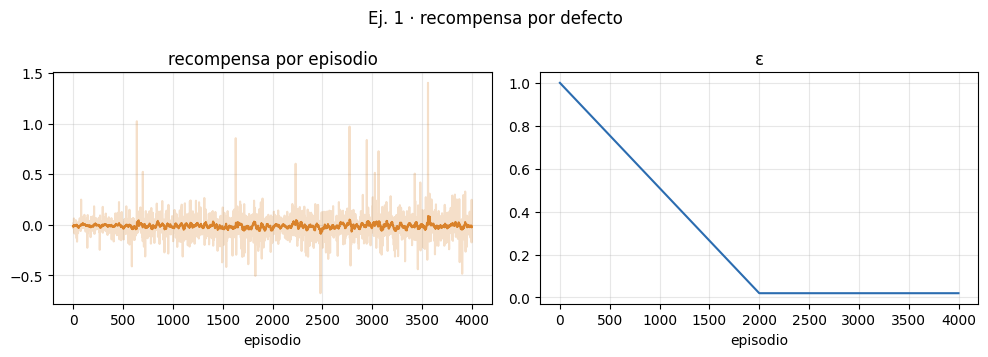

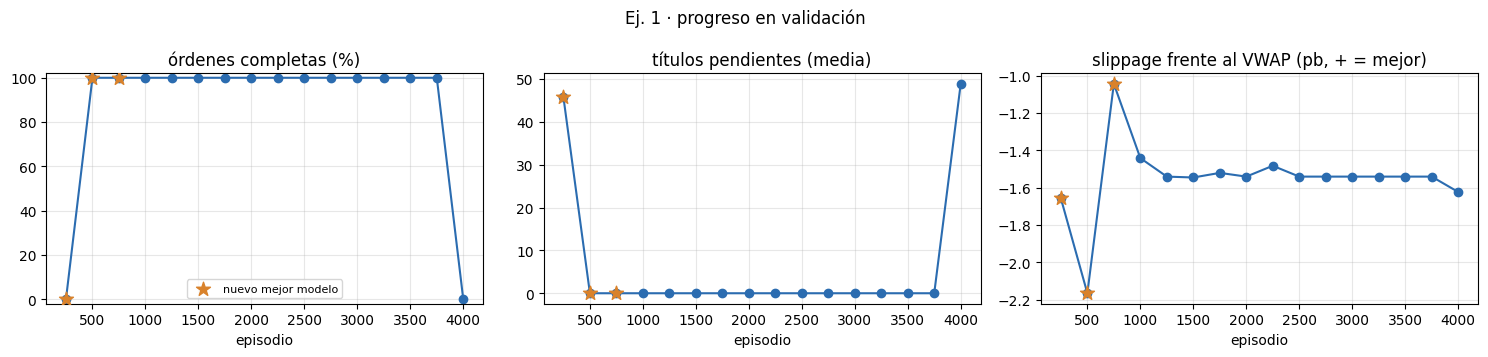

In [16]:
ep, ev = pr.train(agent, env, nepisodes, ex.LinearDecay(epsilon, min_epsilon, epsilon_decay),
                  learn_after=learn_after, update_target_after=update_target_after, log_every=250,
                  eval_data=DATA["val"], eval_grid=GRID_VAL, eval_every=eval_every,
                  eval_reward=rw.Default(), checkpoint=CHECKPOINT,
                  checkpoint_metric="execution", checkpoint_config=CONFIG)
pr.save_df(ep, "ej1_train")
pr.save_df(ev, "ej1_validation")
pl.plot_training(ep, title="Ej. 1 · recompensa por defecto", save="ej1_training")
pl.plot_validation(ev, title="Ej. 1 · progreso en validación", save="ej1_validation")

# Se conserva el último checkpoint y se recupera el elegido SOLO con validación.
best_checkpoint = agent.load(f"{CHECKPOINT}_best.pt")
agent.set_trainable(False)
print(f"Modelo seleccionado: episodio {best_checkpoint['episode']}; "
      f"criterio (completitud, -pendientes, slippage): {best_checkpoint['selection_score']}")
display(ev.tail())


**Cómo leer el entrenamiento.** La primera curva muestra la suma de recompensas de cada episodio,
mezclando exploración, política y órdenes diferentes; no es rentabilidad financiera. La segunda
muestra epsilon. El MSE mide ajuste al objetivo de Bellman: un MSE pequeño no garantiza completar
órdenes, un buen precio de compra ni un reparto regular. Para interpretar la política se necesita
la ejecución sin exploración del siguiente apartado.

La figura de validación muestra siempre las mismas órdenes: completas, pendientes y slippage.
Las estrellas identifican nuevos mejores modelos según el criterio anterior. La curva puede empeorar
al final; por eso las evaluaciones siguientes usan el checkpoint elegido, no necesariamente el último.

## 14. Ejecutar sin aprender y comparar en episodios fijos

**Decisión.** Se evalúa la política con `set_trainable(False)`: `act()` usa la acción de mayor Q,
salvo la primera compra impuesta. `run_episode()` no guarda experiencias ni llama a `learn()`.
`evaluate()` asigna temporalmente el entorno de evaluación al agente y restaura su entorno y modo
anteriores al acabar. Esa asignación importa porque `act()` consulta `env.state_pos`.

**Justificación.** La ejecución final permite observar la política aprendida, sin mezclarla con
acciones exploratorias ni cambiar sus pesos. Durante ella no se necesita la recompensa para decidir;
se calcula para medir lo ocurrido.

La rejilla combina tres días, tres duraciones (400, 500, 600) y tres proporciones de tamaño
(0,075; 0,10; 0,125): 27 episodios por split, con comienzos fijados mediante semilla. DDQN y TWAP
se comparan en exactamente las mismas órdenes. El TWAP determinista compra si `V >= T`, es decir,
si va igual o por detrás de un reparto uniforme (D-1.4). Se utiliza como referencia, no como etiqueta
supervisada para entrenar la red de este ejercicio.

También se ejecuta una rejilla de test separada de train. Es una evaluación descriptiva de este
checkpoint **seleccionado en validación** y estas órdenes, no una garantía de generalización a todas las jornadas ni un estudio
con varias semillas de entrenamiento.

In [17]:
mostrar_codigo(pr.run_episode, pr.evaluate, TWAPAgent.act)

**`run_episode` · `notebooks/common/protocol.py`**

```python
def run_episode(env, agent, cfg=None):
    """Ejecuta un episodio completo con la política actual del agente (sin aprender)."""
    s = env.reset(**{k: cfg[k] for k in ("day", "start_pos", "n_bins", "vol_care")}) if cfg else env.reset()
    ret = 0.0
    while True:
        a = agent.act(s)
        s, r, done, _ = env.step(a)
        ret += r
        if done:
            return ret
```

**`evaluate` · `notebooks/common/protocol.py`**

```python
def evaluate(agent, data, grid, reward=None, obs_mode="TV", with_twap=True) -> pd.DataFrame:
    """Evaluación greedy sobre la rejilla. Usa un entorno propio y reasigna agent.env
    durante la evaluación: DDQNAgent.act consulta env.state_pos (errata E5)."""
    env = BestExecutionEnv(data, reward=reward, seed=0, obs_mode=obs_mode)
    twap_env = BestExecutionEnv(data, reward=reward, seed=0, obs_mode=obs_mode)
    twap = TWAPAgent(twap_env)
    old_env, old_train = getattr(agent, "env", None), getattr(agent, "_trainable", False)
    agent.env = env
    agent.set_trainable(False)
    rows = []
    try:
        for i, cfg in enumerate(grid):
            ret = run_episode(env, agent, cfg)
            m = {"ep": i, "day": str(cfg["day"]), "rho": cfg["rho"], **episode_metrics(env, ret)}
            if with_twap:
                run_episode(twap_env, twap, cfg)
                tw = episode_metrics(twap_env)
                m["slippage_vs_twap_bps"] = (tw["algo_vwap"] - m["algo_vwap"]) / tw["algo_vwap"] * 1e4 \
                    if np.isfinite(m["algo_vwap"]) else np.nan
            rows.append(m)
    finally:
        agent.env = old_env
        agent.set_trainable(old_train)
    return pd.DataFrame(rows)
```

**`TWAPAgent.act` · `notebooks/common/agents.py`**

```python
def act(self, s) -> int:
    return int(s[1] >= s[0] - 1e-9)
```

In [18]:
GRID = pr.make_grid(train, n_days=3, seed=0)
res = pr.evaluate(agent, train, GRID, reward=rw.Default(), obs_mode=OBS_MODE)
pr.save_df(res, "ej1_eval_train")
res_twap = pr.evaluate(TWAPAgent(), train, GRID, reward=rw.Default(), obs_mode=OBS_MODE,
                       with_twap=False)

GRID_TEST = pr.make_grid(DATA["test"], n_days=3, seed=0)
res_test = pr.evaluate(agent, DATA["test"], GRID_TEST, reward=rw.Default(), obs_mode=OBS_MODE)
pr.save_df(res_test, "ej1_eval_test")
print(f"Rejilla de train: {len(GRID)} órdenes; rejilla de test: {len(GRID_TEST)} órdenes")
display(pd.DataFrame({"DDQN train": pr.summarize(res),
                      "TWAP train": pr.summarize(res_twap),
                      "DDQN test": pr.summarize(res_test)}))

Rejilla de train: 27 órdenes; rejilla de test: 27 órdenes


,DDQN train,TWAP train,DDQN test
completed_mean,1.000,1.000,1.000
completed_std,0.000,0.000,0.000
max_err_mean,32.034,0.900,32.034
max_err_std,7.370,0.021,7.370
mean_err_mean,18.088,0.437,18.088
mean_err_std,3.983,0.017,3.983
n_buys_mean,49.889,49.889,49.889
n_buys_std,13.429,13.429,13.429
pending_mean,0.000,0.000,0.000
pending_std,0.000,0.000,0.000


**Qué significan las métricas:**

| Métrica | Interpretación |
|---|---|
| `completed` / `pending` | Si se compró todo y cuántos títulos faltan. |
| `t_fin` | Fracción del plazo consumida; 0,10 significa terminar al 10 % del tiempo. |
| `max_err` / `mean_err` | Desviación en títulos frente a un plan TWAP, medida sobre todo el horizonte. |
| `n_buys` / `gap_mean` / `gap_std` | Número de compras y separación entre ellas, en pasos. |
| `slippage_bps` | `(VWAP mercado − VWAP algoritmo) / VWAP mercado * 10000`; positivo significa comprar más barato. |
| `slippage_vs_twap_bps` | Ventaja de precio frente al TWAP que ejecuta la misma orden; positivo favorece al agente. |

El error frente al TWAP es un diagnóstico, no la recompensa que se optimiza aquí. Para medir ese
error se mantiene el volumen ejecutado final hasta el fin del horizonte, aunque la orden termine antes.
Una separación constante entre compras tampoco basta: comprar en todos los pasos iniciales es regular
localmente, pero no reparte la orden por todo el plazo.

In [19]:
mostrar_codigo(pr.episode_metrics)
# Comentario de resultados calculado a partir de esta ejecución, no de cifras copiadas.
for nombre, tabla in (("DDQN train", res), ("DDQN test", res_test), ("TWAP train", res_twap)):
    print(f"{nombre}: completas {int(tabla.completed.sum())}/{len(tabla)}, "
          f"pendientes medios {tabla.pending.mean():.2f}, "
          f"final al {100 * tabla.t_fin.mean():.1f}% del plazo, "
          f"error máximo medio {tabla.max_err.mean():.2f} títulos")

**`episode_metrics` · `notebooks/common/protocol.py`**

```python
def episode_metrics(env, ret=np.nan) -> dict:
    N, n = env.episode_bins, env.vol_care
    e = trajectory(env)
    plan = np.minimum(n, np.arange(1, N + 1) * n / N)
    err = np.abs(e - plan)
    buys = np.flatnonzero(np.asarray(env.vol_hist) > 0)
    gaps = np.diff(buys)
    gap_mean, gap_std = (float(gaps.mean()), float(gaps.std())) if len(gaps) else (np.nan, np.nan)
    algo = env._compute_algo_vwap()
    return {
        "N": N, "n": n, "return": ret,
        "completed": bool(env.exec_vol >= n), "pending": int(n - env.exec_vol),
        "t_fin": len(env.vol_hist) / N,
        "max_err": float(err.max()), "mean_err": float(err.mean()),
        "n_buys": int(len(buys)), "gap_mean": gap_mean, "gap_std": gap_std,
        "algo_vwap": algo, "mkt_vwap": env.episode_vwap,
        "slippage_bps": (env.episode_vwap - algo) / env.episode_vwap * 1e4 if np.isfinite(algo) else np.nan,
    }
```

DDQN train: completas 27/27, pendientes medios 0.00, final al 35.0% del plazo, error máximo medio 32.03 títulos
DDQN test: completas 27/27, pendientes medios 0.00, final al 35.0% del plazo, error máximo medio 32.03 títulos
TWAP train: completas 27/27, pendientes medios 0.00, final al 98.1% del plazo, error máximo medio 0.90 títulos


**Lectura de las figuras.** Arriba se comparan el precio medio de nuestras compras, el VWAP de
mercado acumulado y el mid. El VWAP acumulado dibujado evoluciona en el tiempo; la recompensa usa
el VWAP final de todo el episodio. Abajo se ve la fracción de nuestra orden ejecutada, el volumen
acumulado relativo del mercado y los instantes de compra. La curva de volumen del mercado no es
el plan TWAP: este sería una diagonal en tiempo normalizado. Los gráficos siguientes ilustran una
orden de train y otra de test; la tabla anterior cubre el conjunto de las rejillas.

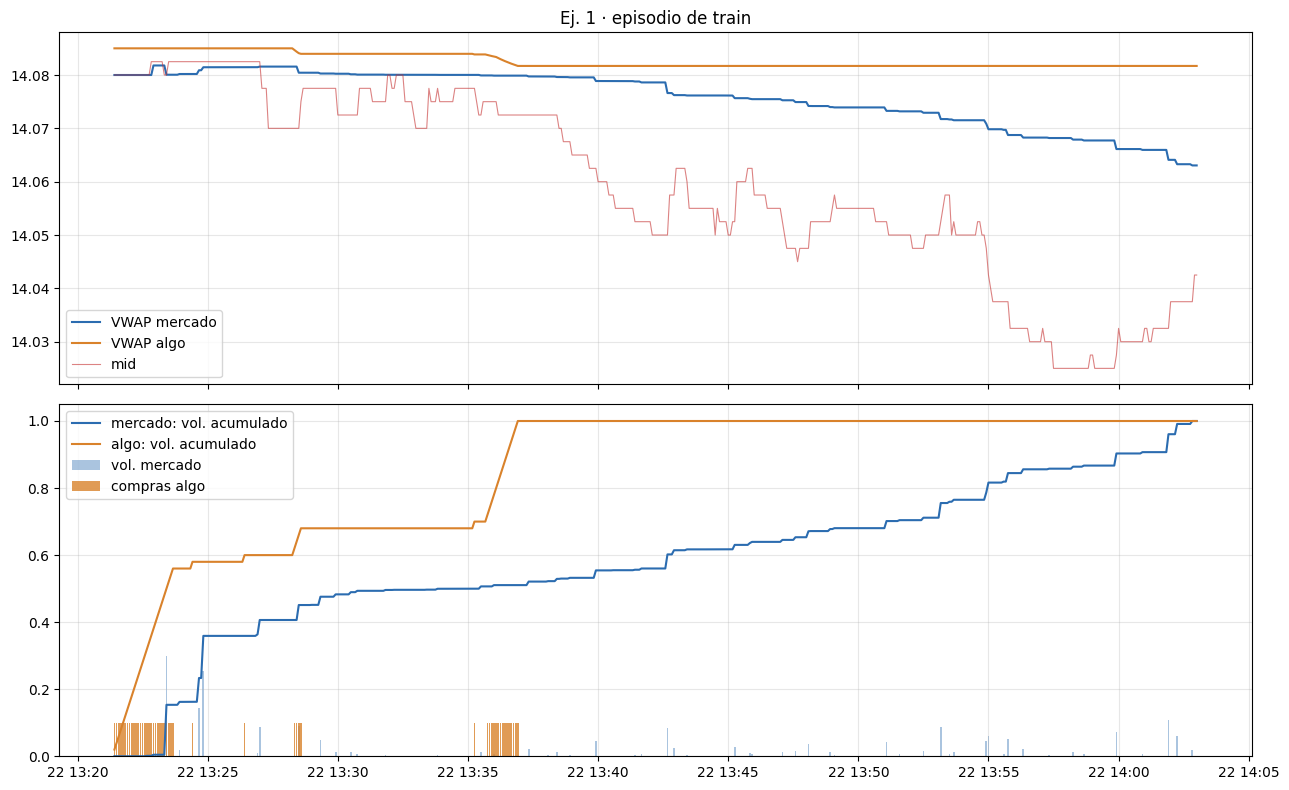

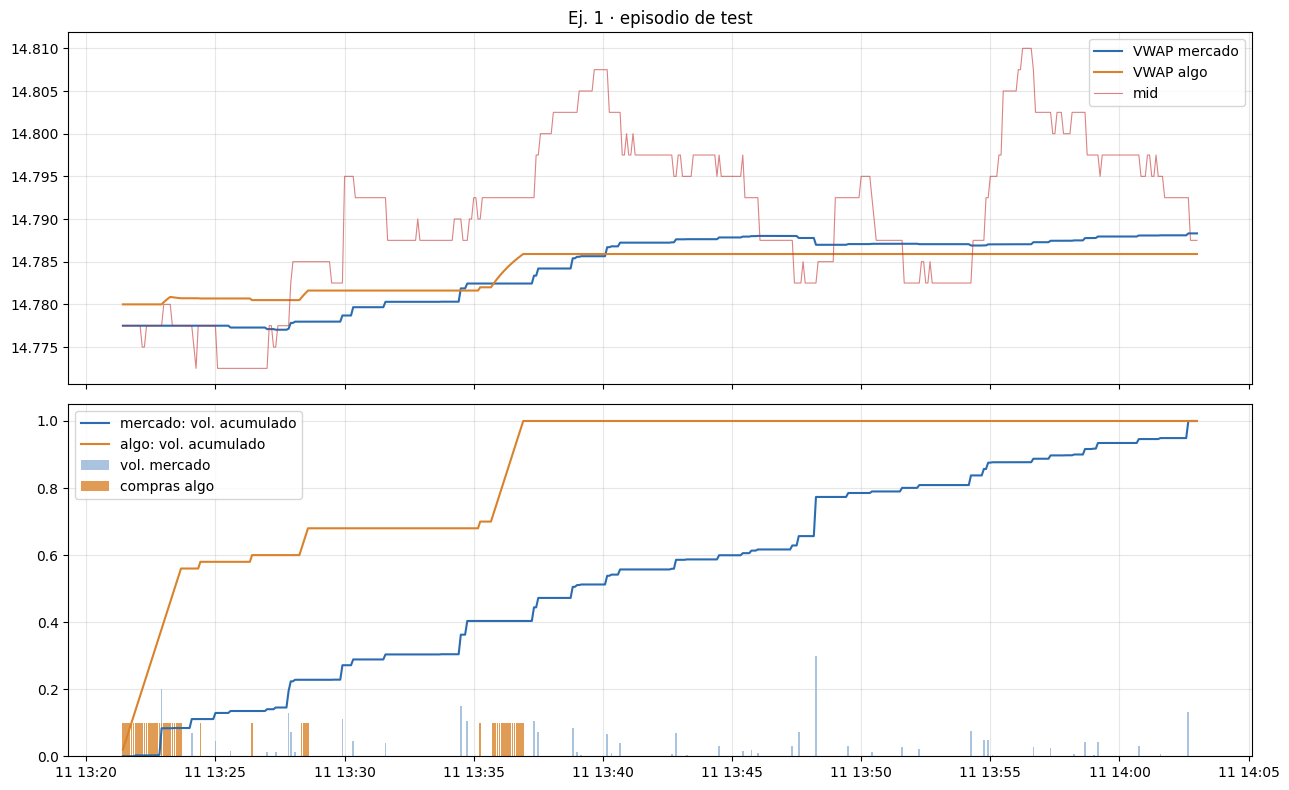

In [20]:
env_tr = BestExecutionEnv(train, seed=1, reward=rw.Default(), obs_mode=OBS_MODE)
agent.env = env_tr
agent.set_trainable(False)
pr.run_episode(env_tr, agent, GRID[4])
pl.plot_results(env_tr, title="Ej. 1 · episodio de train", save="ej1_episodio_train");

env_te = BestExecutionEnv(DATA["test"], seed=1, reward=rw.Default(), obs_mode=OBS_MODE)
agent.env = env_te
pr.run_episode(env_te, agent, GRID_TEST[4])
pl.plot_results(env_te, title="Ej. 1 · episodio de test", save="ej1_episodio_test");

## 15. Fijar la semilla y guardar el modelo y la configuración

**Decisión.** Se utiliza `SEED=0`, semillas propias para entorno y agente, y un solo hilo de PyTorch.
La fijación de semillas ya se ejecutó en el apartado 13, **antes** de inicializar la red. Se explica
aquí junto al guardado para cerrar las 15 decisiones; fijarla solo después de entrenar no reproduciría
la inicialización ni el recorrido anterior.

**Justificación.** Controlar la aleatoriedad permite repetir este experimento. El entorno y el agente
tienen instancias separadas de `np.random.default_rng(seed)` (D-1.3): las llamadas de exploración
no consumen los números destinados a seleccionar nuevos episodios. Esto mantiene el sorteo de las
órdenes independiente de cuántas veces se explore. La semilla de la rejilla fija las órdenes evaluadas.
Una sola semilla no demuestra robustez, y reproducir entre versiones o equipos distintos puede requerir
controlar también esas dependencias.

Guardamos los pesos de ambas redes, el estado de Adam, epsilon y `CONFIG`; también las métricas y
las figuras. El JSON incluye huellas SHA-256 de los módulos empleados, para identificar el código
de la ejecución. Por defecto se escribe en `results/` desde `protocol`.

**Alcance de la recuperación.** `load()` restaura redes, optimizador y epsilon para recuperar el
modelo. El checkpoint actual no incluye el buffer, los estados de los generadores ni los contadores
del entrenamiento: permite reutilizar la política, pero no garantiza reanudar exactamente la misma
trayectoria de aprendizaje paso a paso.

Se conservan por separado `ej1_ddqn_last.pt` (último) y `ej1_ddqn_best.pt` (mejor en validación).
El archivo habitual `ej1_ddqn.pt` se guarda como copia del **seleccionado** para que su evaluación
coincida con las tablas y figuras. Los checkpoints incluyen episodio, criterio, métricas de validación
y configuración. El CSV `ej1_validation.csv` conserva el progreso observado durante el entrenamiento.

In [21]:
mostrar_codigo(pr.set_seeds)
# Los dos constructores crean generadores distintos, aunque reciban la misma semilla.
mostrar_codigo(BestExecutionEnv.__init__, desde="self.rng =", hasta="self.reward =")
mostrar_codigo(DDQNAgent.__init__, desde="self.rng =", hasta="self.primary_model =")
mostrar_codigo(DDQNAgent.save, DDQNAgent.load)

**`set_seeds` · `notebooks/common/protocol.py`**

```python
def set_seeds(seed: int):
    np.random.seed(seed)
    torch.manual_seed(seed)
```

**`BestExecutionEnv.__init__` · `notebooks/common/env.py`**

```python
self.rng = np.random.default_rng(seed)  # [MOD]
```

**`DDQNAgent.__init__` · `notebooks/common/agents.py`**

```python
self.rng = np.random.default_rng(seed)  # [MOD]
    if seed is not None:
        torch.manual_seed(seed)
```

**`DDQNAgent.save` · `notebooks/common/agents.py`**

```python
def save(self, path, **extra):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"primary": self.primary_model.state_dict(), "target": self.target_model.state_dict(),
                "optimizer": self.optimizer.state_dict(), "epsilon": self.epsilon, **extra}, path)
```

**`DDQNAgent.load` · `notebooks/common/agents.py`**

```python
def load(self, path) -> dict:
    ckpt = torch.load(path, weights_only=False)
    self.primary_model.load_state_dict(ckpt["primary"])
    self.target_model.load_state_dict(ckpt["target"])
    self.optimizer.load_state_dict(ckpt["optimizer"])
    self.epsilon = ckpt["epsilon"]
    return ckpt
```

In [22]:
CONFIG["selected_episode"] = best_checkpoint["episode"]
CONFIG["selection_score"] = best_checkpoint["selection_score"]
pr.save_json(CONFIG, "ej1_config")
selected_metadata = {k: best_checkpoint[k]
                     for k in ("episode", "metric", "checkpoint_metric", "selection_score", "validation")}
agent.save(pr.MODELS / "ej1_ddqn.pt", config=CONFIG, **selected_metadata)

display(pd.Series({
    "configuración": "ej1_config.json",
    "modelo seleccionado": "models/ej1_ddqn.pt y models/ej1_ddqn_best.pt",
    "modelo último": "models/ej1_ddqn_last.pt",
    "entrenamiento": "ej1_train.csv",
    "progreso en validación": "ej1_validation.csv",
    "evaluación": "ej1_eval_train.csv y ej1_eval_test.csv",
    "figuras": "figures/ej1_training.png, ej1_validation.png y episodios de train/test"
}, name="Archivos generados"))


configuración                                               ej1_config.json
modelo seleccionado            models/ej1_ddqn.pt y models/ej1_ddqn_best.pt
modelo último                                       models/ej1_ddqn_last.pt
entrenamiento                                                 ej1_train.csv
progreso en validación                                   ej1_validation.csv
evaluación                           ej1_eval_train.csv y ej1_eval_test.csv
figuras                   figures/ej1_training.png, ej1_validation.png y...
Name: Archivos generados, dtype: object

**Qué queda demostrado y qué queda pendiente.** El notebook ejecuta el circuito completo:
datos históricos → episodio → observación → acción → ejecución y recompensa → memoria →
actualizaciones Double DQN → validación periódica → selección del mejor modelo → evaluación sin aprendizaje → guardado. Aprende durante los episodios,
no solo después de terminarlos. Los resultados se interpretan con las métricas y figuras obtenidas
arriba, sin confundir completar órdenes con repartirlas bien.

La red ve `[T, V]`, mientras que el entorno usa precios y volumen histórico para simular y evaluar.
Por esa diferencia de información, este ejercicio no demuestra una estrategia capaz de anticipar
precios. La recompensa tampoco exige una trayectoria TWAP. El siguiente ejercicio alinea el estado
y la recompensa con ese objetivo de reparto, manteniendo el circuito de interacción y aprendizaje.

**Comprobación directa del aprendizaje.** Desde `notebooks/`, ejecutar:

```bash
python -m unittest common.test_env common.test_learning common.test_protocol common.test_ej4 -v
```

`test_learning` utiliza redes con Q conocidas: la principal elige la acción 0 aunque la objetivo
prefiere la 1. Comprueba el objetivo `3 + 0,5 × 5 = 5,5`, el objetivo terminal `-2`, el MSE exacto,
los gradientes solo por las Q ejecutadas y la copia de la red objetivo. `test_protocol` comprueba
que un precio favorable no compense órdenes incompletas, que el mejor checkpoint sobreviva a un
empeoramiento y que el último corresponda al episodio final aunque no sea múltiplo de la frecuencia
de evaluación. Una prueba con datos reales confirma que validar no altera el aprendizaje ni sus
generadores aleatorios. Estas comprobaciones no demuestran calidad financiera.
